In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/afaq-ahmad/Hotel-booking-demand-Case-Study/master/H2.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (79330, 31)


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [2]:
#  DATA understanding
# Step 1: Dataset Overview

print("=" * 50)
print("CITY HOTEL DATASET OVERVIEW")
print("=" * 50)

print("Total Bookings:", df.shape[0])
print("Total Features:", df.shape[1])

print("\nCOLUMN NAMES:")
for i, column in enumerate(df.columns, 1):
    print(f"{i}. {column}")

print("\nDATA TYPES:")
display(pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Unique Values": df.nunique(dropna=True).values
}))

CITY HOTEL DATASET OVERVIEW
Total Bookings: 79330
Total Features: 31

COLUMN NAMES:
1. IsCanceled
2. LeadTime
3. ArrivalDateYear
4. ArrivalDateMonth
5. ArrivalDateWeekNumber
6. ArrivalDateDayOfMonth
7. StaysInWeekendNights
8. StaysInWeekNights
9. Adults
10. Children
11. Babies
12. Meal
13. Country
14. MarketSegment
15. DistributionChannel
16. IsRepeatedGuest
17. PreviousCancellations
18. PreviousBookingsNotCanceled
19. ReservedRoomType
20. AssignedRoomType
21. BookingChanges
22. DepositType
23. Agent
24. Company
25. DaysInWaitingList
26. CustomerType
27. ADR
28. RequiredCarParkingSpaces
29. TotalOfSpecialRequests
30. ReservationStatus
31. ReservationStatusDate

DATA TYPES:


,Feature,Data Type,Non-Null Count,Unique Values
0,IsCanceled,int64,79330,2
1,LeadTime,int64,79330,453
2,ArrivalDateYear,int64,79330,3
3,ArrivalDateMonth,object,79330,12
4,ArrivalDateWeekNumber,int64,79330,53
5,ArrivalDateDayOfMonth,int64,79330,31
6,StaysInWeekendNights,int64,79330,14
7,StaysInWeekNights,int64,79330,29
8,Adults,int64,79330,5
9,Children,float64,79326,4


In [4]:
# Step 2: Descriptive Statistics

print("NUMERICAL FEATURES STATISTICS")

display(
    df.describe().T.round(2)
)

print("\nCATEGORICAL FEATURES STATISTICS")

display(
    df.describe(include=["object", "category"]).T
)

NUMERICAL FEATURES STATISTICS


,count,mean,std,min,25%,50%,75%,max
IsCanceled,79330.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
LeadTime,79330.0,109.74,110.95,0.0,23.0,74.0,163.0,629.0
ArrivalDateYear,79330.0,2016.17,0.70,2015.0,2016.0,2016.0,2017.0,2017.0
ArrivalDateWeekNumber,79330.0,27.18,13.40,1.0,17.0,27.0,38.0,53.0
ArrivalDateDayOfMonth,79330.0,15.79,8.73,1.0,8.0,16.0,23.0,31.0
StaysInWeekendNights,79330.0,0.80,0.89,0.0,0.0,1.0,2.0,16.0
StaysInWeekNights,79330.0,2.18,1.46,0.0,1.0,2.0,3.0,41.0
Adults,79330.0,1.85,0.51,0.0,2.0,2.0,2.0,4.0
Children,79326.0,0.09,0.37,0.0,0.0,0.0,0.0,3.0
Babies,79330.0,0.00,0.08,0.0,0.0,0.0,0.0,10.0



CATEGORICAL FEATURES STATISTICS


,count,unique,top,freq
ArrivalDateMonth,79330,12,August,8983
Meal,79330,4,BB,62305
Country,79306,166,PRT,30960
MarketSegment,79330,8,Online TA,38748
DistributionChannel,79330,5,TA/TO,68945
ReservedRoomType,79330,8,A,62595
AssignedRoomType,79330,9,A,57007
DepositType,79330,3,No Deposit,66442
Agent,79330,224,9,31955
Company,79330,208,NULL,75641


In [5]:
# Step 3: Missing Values Analysis

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_values.round(2))

,Missing Count,Missing Percentage
Country,24,0.03
Children,4,0.01
IsCanceled,0,0.00
ArrivalDateMonth,0,0.00
ArrivalDateWeekNumber,0,0.00
LeadTime,0,0.00
ArrivalDateYear,0,0.00
StaysInWeekendNights,0,0.00
ArrivalDateDayOfMonth,0,0.00
Adults,0,0.00


In [6]:
# Task 2.1: Hidden Missing Values

missing_markers = [
    "NULL", "null", "None", "none",
    "N/A", "n/a", "NA", "nan",
    "NaN", "", " "
]

print("HIDDEN MISSING VALUES")
print("=" * 50)

for col in df.select_dtypes(include=["object"]).columns:

    values = df[col].astype("string").str.strip()

    hidden_missing = values.isin(missing_markers).sum()

    if hidden_missing > 0:
        print(
            f"{col}: {hidden_missing} "
            f"({hidden_missing / len(df) * 100:.2f}%)"
        )

HIDDEN MISSING VALUES
Agent: 8131 (10.25%)
Company: 75641 (95.35%)


In [7]:
# Task 2.2: Duplicate Records

duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print("DATASET DUPLICATES")
print("=" * 50)

print("Total Records:", len(df))

print("Duplicate Records:", duplicate_count)

print(
    f"Duplicate Percentage: "
    f"{duplicate_percentage:.2f}%"
)

DATASET DUPLICATES
Total Records: 79330
Duplicate Records: 25902
Duplicate Percentage: 32.65%


In [8]:
# Task 2.3: Invalid and Suspicious Values

print("INVALID / SUSPICIOUS VALUES")
print("=" * 50)

checks = {
    "Negative LeadTime":
        (df["LeadTime"] < 0).sum(),

    "Negative ADR":
        (df["ADR"] < 0).sum(),

    "Zero Total Guests":
        (
            df["Adults"].fillna(0)
            + df["Children"].fillna(0)
            + df["Babies"].fillna(0)
            == 0
        ).sum(),

    "Negative Adults":
        (df["Adults"] < 0).sum(),

    "Negative Children":
        (df["Children"] < 0).sum(),

    "Negative Babies":
        (df["Babies"] < 0).sum(),

    "Zero Total Nights":
        (
            df["StaysInWeekendNights"]
            + df["StaysInWeekNights"]
            == 0
        ).sum(),

    "ADR Greater Than 1000":
        (df["ADR"] > 1000).sum()
}

quality_checks = pd.DataFrame(
    list(checks.items()),
    columns=["Quality Check", "Count"]
)

quality_checks["Percentage"] = (
    quality_checks["Count"] / len(df) * 100
).round(3)

display(quality_checks)

INVALID / SUSPICIOUS VALUES


,Quality Check,Count,Percentage
0,Negative LeadTime,0,0.000
1,Negative ADR,0,0.000
2,Zero Total Guests,167,0.211
3,Negative Adults,0,0.000
4,Negative Children,0,0.000
5,Negative Babies,0,0.000
6,Zero Total Nights,331,0.417
7,ADR Greater Than 1000,1,0.001


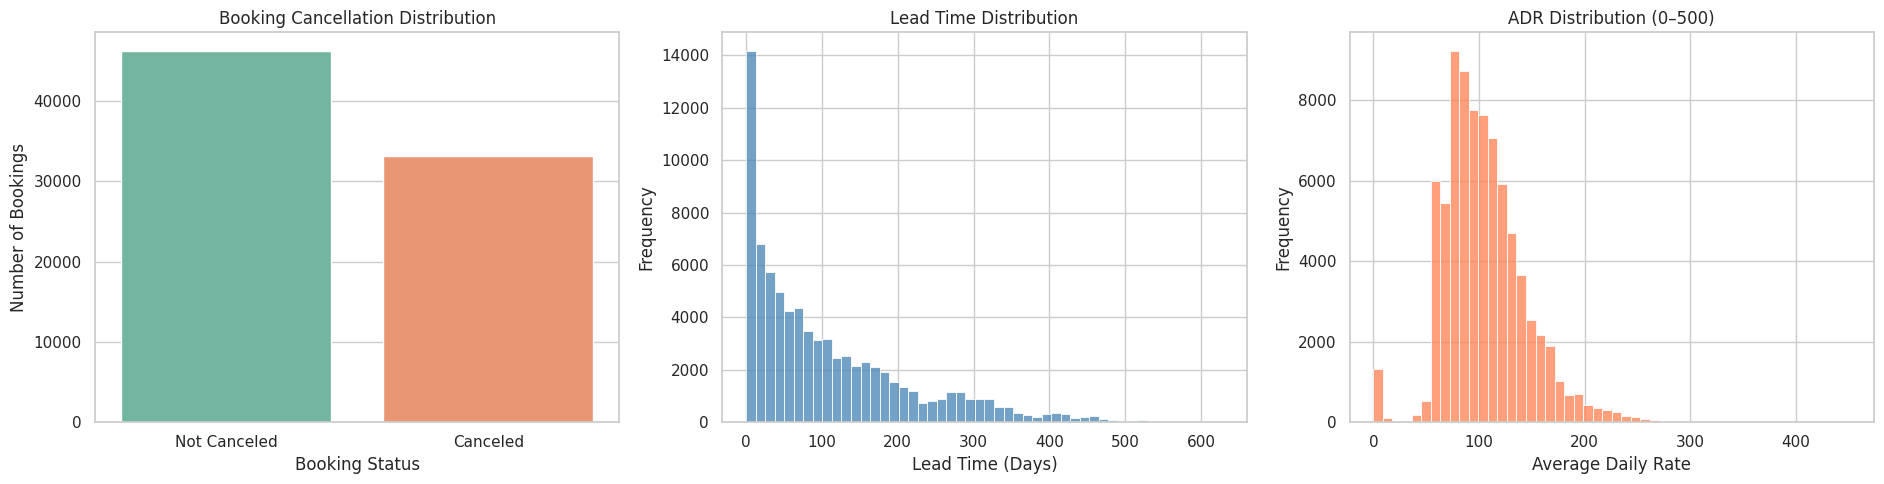

In [9]:
# Task 3.1: Numerical and Target Distributions

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Cancellation Distribution
sns.countplot(
    data=df,
    x="IsCanceled",
    hue="IsCanceled",
    palette="Set2",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Booking Cancellation Distribution")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Not Canceled", "Canceled"])
axes[0].set_xlabel("Booking Status")
axes[0].set_ylabel("Number of Bookings")

# 2. Lead Time Distribution
sns.histplot(
    data=df,
    x="LeadTime",
    bins=50,
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Lead Time Distribution")
axes[1].set_xlabel("Lead Time (Days)")
axes[1].set_ylabel("Frequency")

# 3. ADR Distribution
sns.histplot(
    data=df[df["ADR"].between(0, 500)],
    x="ADR",
    bins=50,
    color="coral",
    ax=axes[2]
)

axes[2].set_title("ADR Distribution (0–500)")
axes[2].set_xlabel("Average Daily Rate")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [10]:
# Task 3.2: Outlier Detection Using IQR

features = [
    "LeadTime",
    "ADR",
    "StaysInWeekNights",
    "StaysInWeekendNights",
    "DaysInWaitingList"
]

results = []

for col in features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    results.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": outliers.sum(),
        "Outlier %": round(
            outliers.mean() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(results)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,LeadTime,-187.0,373.0,2576,3.25
1,ADR,9.0,196.2,3387,4.27
2,StaysInWeekNights,-2.0,6.0,719,0.91
3,StaysInWeekendNights,-3.0,5.0,82,0.10
4,DaysInWaitingList,0.0,0.0,3443,4.34


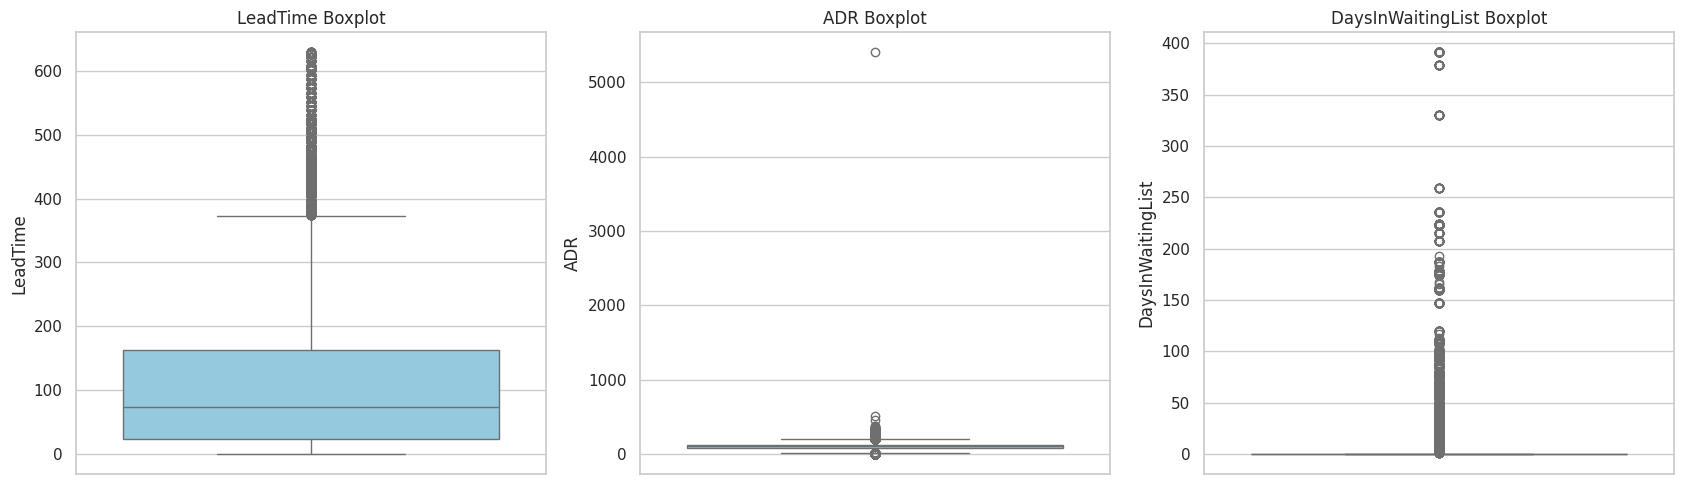

In [11]:
# Task 3.3: Boxplots

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

features = [
    "LeadTime",
    "ADR",
    "DaysInWaitingList"
]

for i, col in enumerate(features):

    sns.boxplot(
        y=df[col],
        color="skyblue",
        ax=axes[i]
    )

    axes[i].set_title(f"{col} Boxplot")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

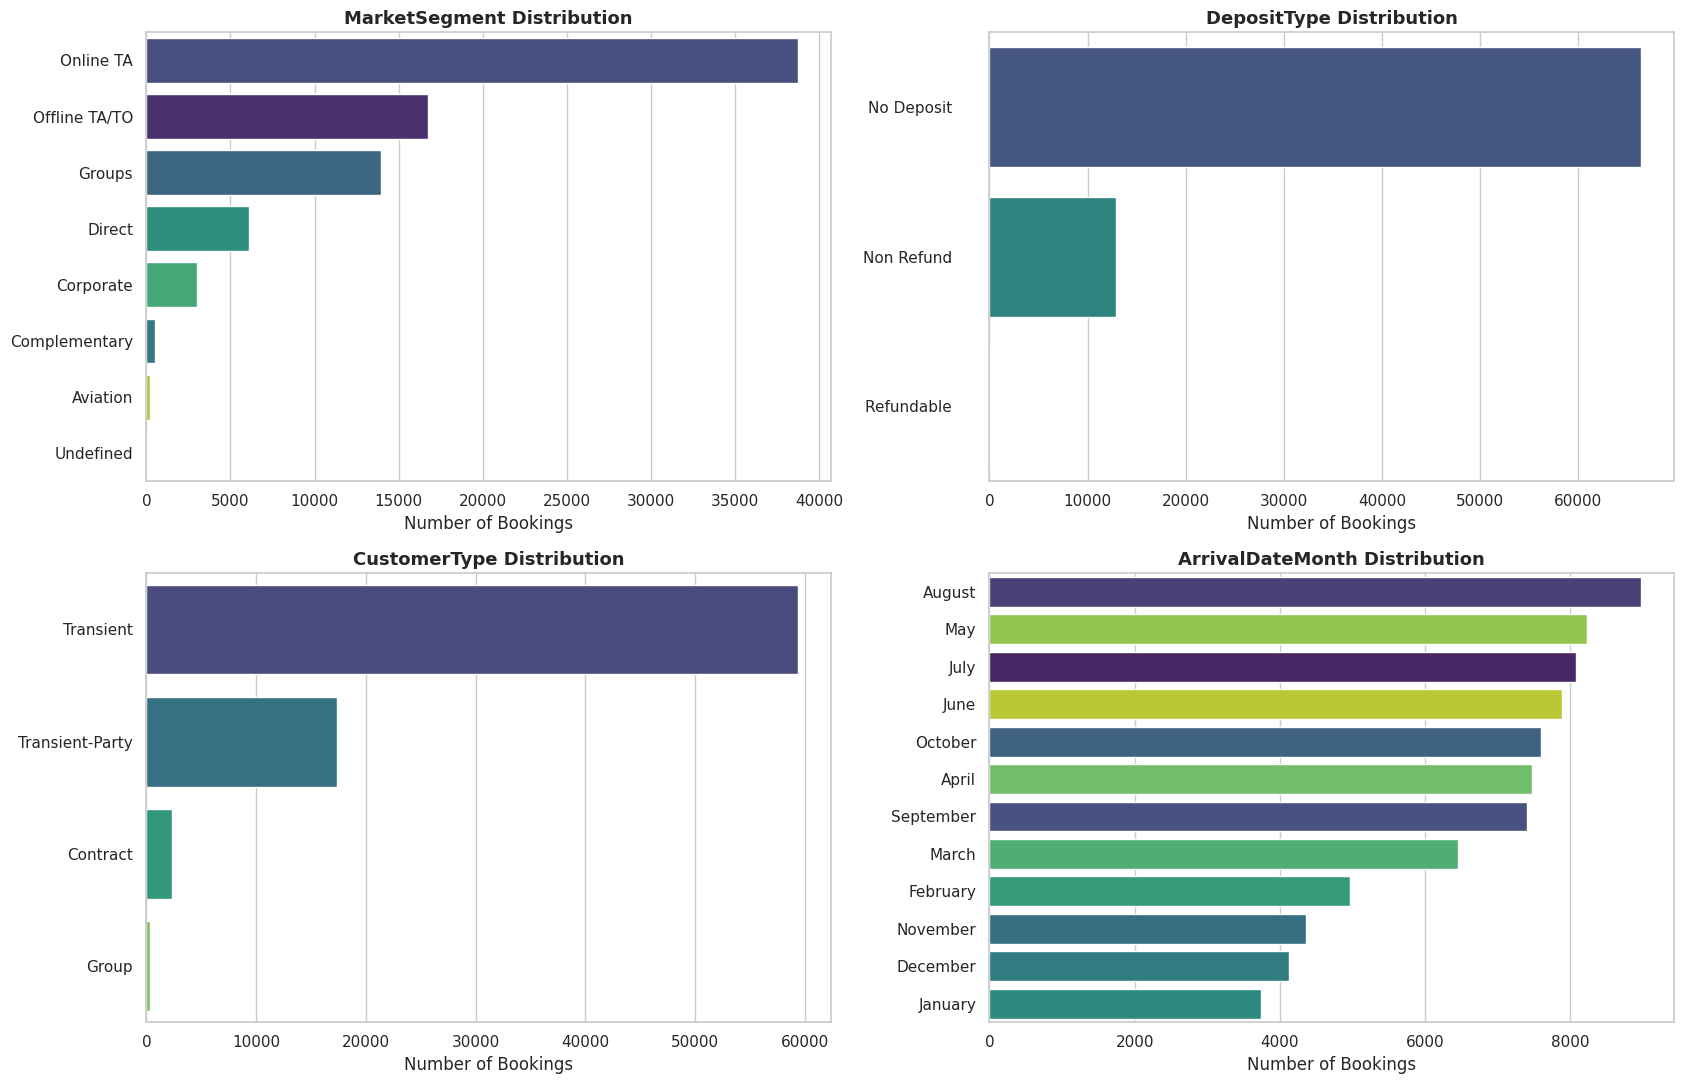

In [12]:
# Task 3.4: Categorical Feature Analysis

categorical_features = [
    "MarketSegment",
    "DepositType",
    "CustomerType",
    "ArrivalDateMonth"
]

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        hue=col,
        order=order,
        palette="viridis",
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{col} Distribution",
        fontsize=13,
        fontweight="bold"
    )

    axes[i].set_xlabel("Number of Bookings")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()


MarketSegment Cancellation Analysis


,MarketSegment,count,CancellationRate
7,Undefined,2,100.00
4,Groups,13975,68.86
5,Offline TA/TO,16747,42.83
6,Online TA,38748,37.40
0,Aviation,237,21.94
2,Corporate,2986,21.47
3,Direct,6093,17.33
1,Complementary,542,11.81



DepositType Cancellation Analysis


,DepositType,count,CancellationRate
1,Non Refund,12868,99.81
2,Refundable,20,70.00
0,No Deposit,66442,30.47



CustomerType Cancellation Analysis


,CustomerType,count,CancellationRate
0,Contract,2300,48.04
2,Transient,59404,45.62
3,Transient-Party,17333,28.10
1,Group,293,9.90


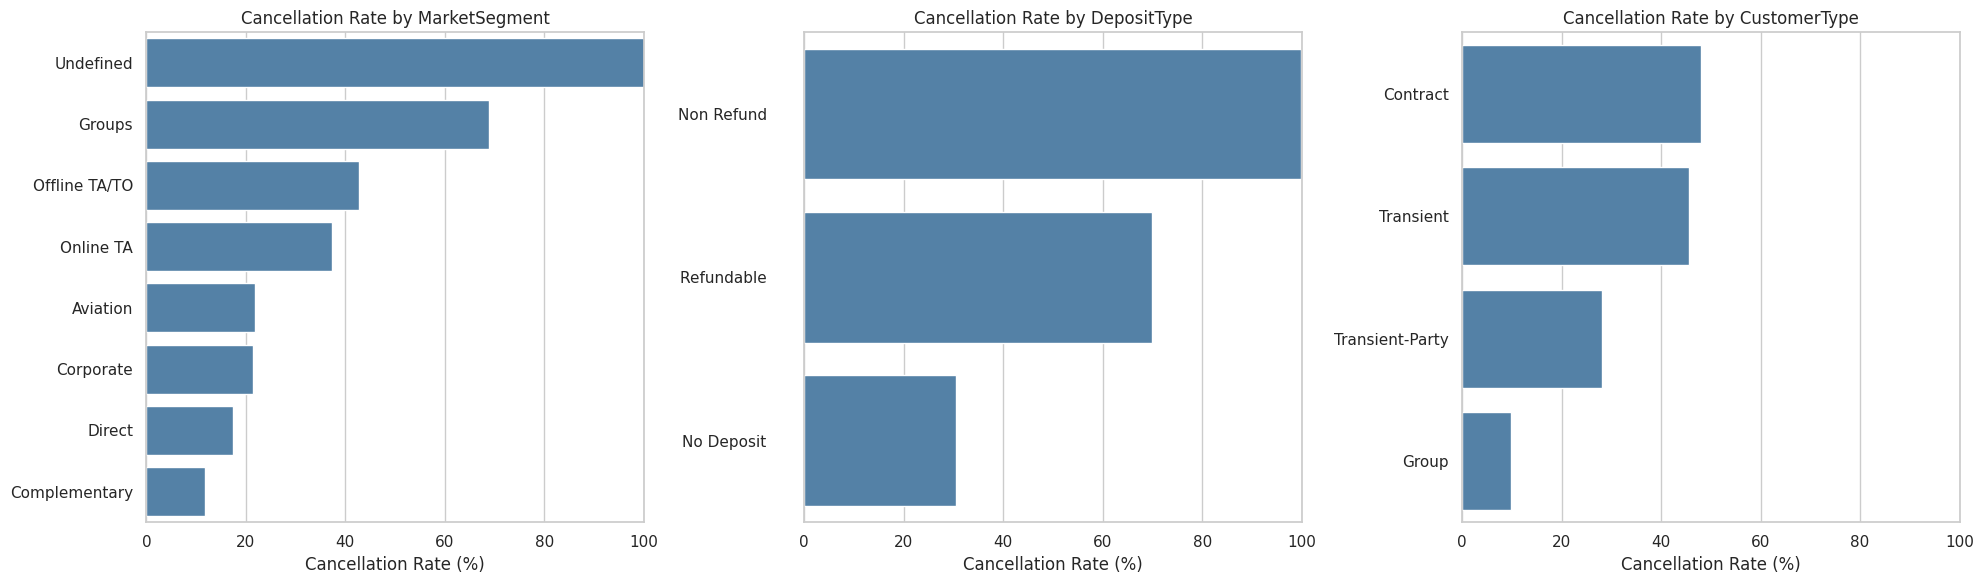

In [13]:
# Task 3.5: Cancellation Rate Analysis

features = [
    "MarketSegment",
    "DepositType",
    "CustomerType"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(features):

    cancellation = (
        df.groupby(col)["IsCanceled"]
        .agg(["mean", "count"])
        .reset_index()
    )

    cancellation["CancellationRate"] = (
        cancellation["mean"] * 100
    )

    cancellation = cancellation.sort_values(
        "CancellationRate",
        ascending=False
    )

    sns.barplot(
        data=cancellation,
        y=col,
        x="CancellationRate",
        color="steelblue",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Cancellation Rate by {col}"
    )

    axes[i].set_xlabel("Cancellation Rate (%)")
    axes[i].set_ylabel("")
    axes[i].set_xlim(0, 100)

    print(f"\n{col} Cancellation Analysis")

    display(
        cancellation[
            [col, "count", "CancellationRate"]
        ].round(2)
    )

plt.tight_layout()
plt.show()

,mean,count,CancellationRate
ArrivalDateMonth,,,
January,0.40,3736,39.67
February,0.38,4965,38.29
March,0.37,6458,36.95
April,0.46,7480,46.32
May,0.44,8232,44.38
June,0.45,7894,44.69
July,0.41,8088,40.88
August,0.40,8983,40.10
September,0.42,7400,42.03


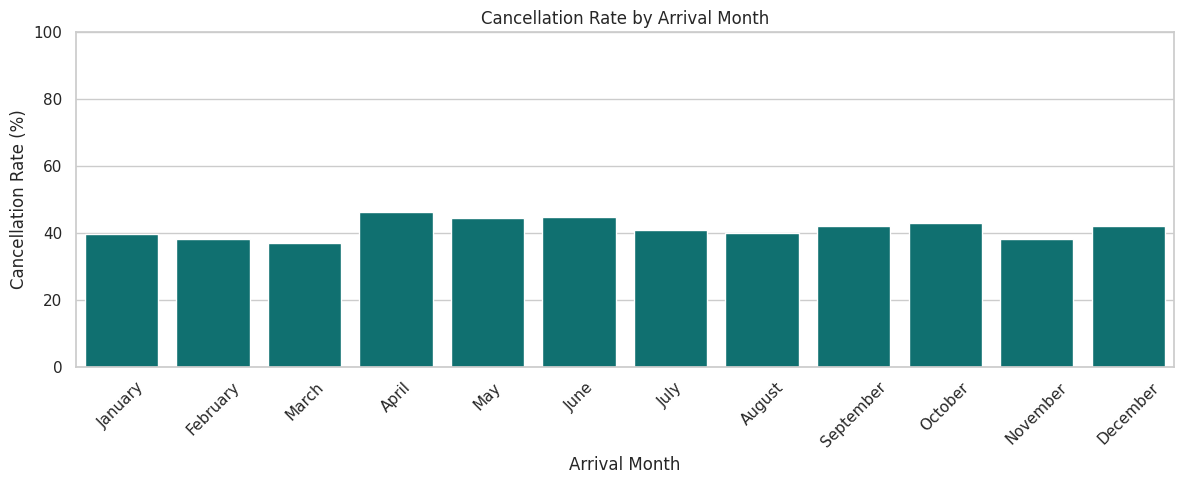

In [14]:
# Task 3.6: Monthly Cancellation Rate

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_cancel = (
    df.groupby("ArrivalDateMonth")["IsCanceled"]
    .agg(["mean", "count"])
    .reindex(month_order)
)

monthly_cancel["CancellationRate"] = (
    monthly_cancel["mean"] * 100
)

display(monthly_cancel.round(2))

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_cancel.index,
    y=monthly_cancel["CancellationRate"],
    color="teal"
)

plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

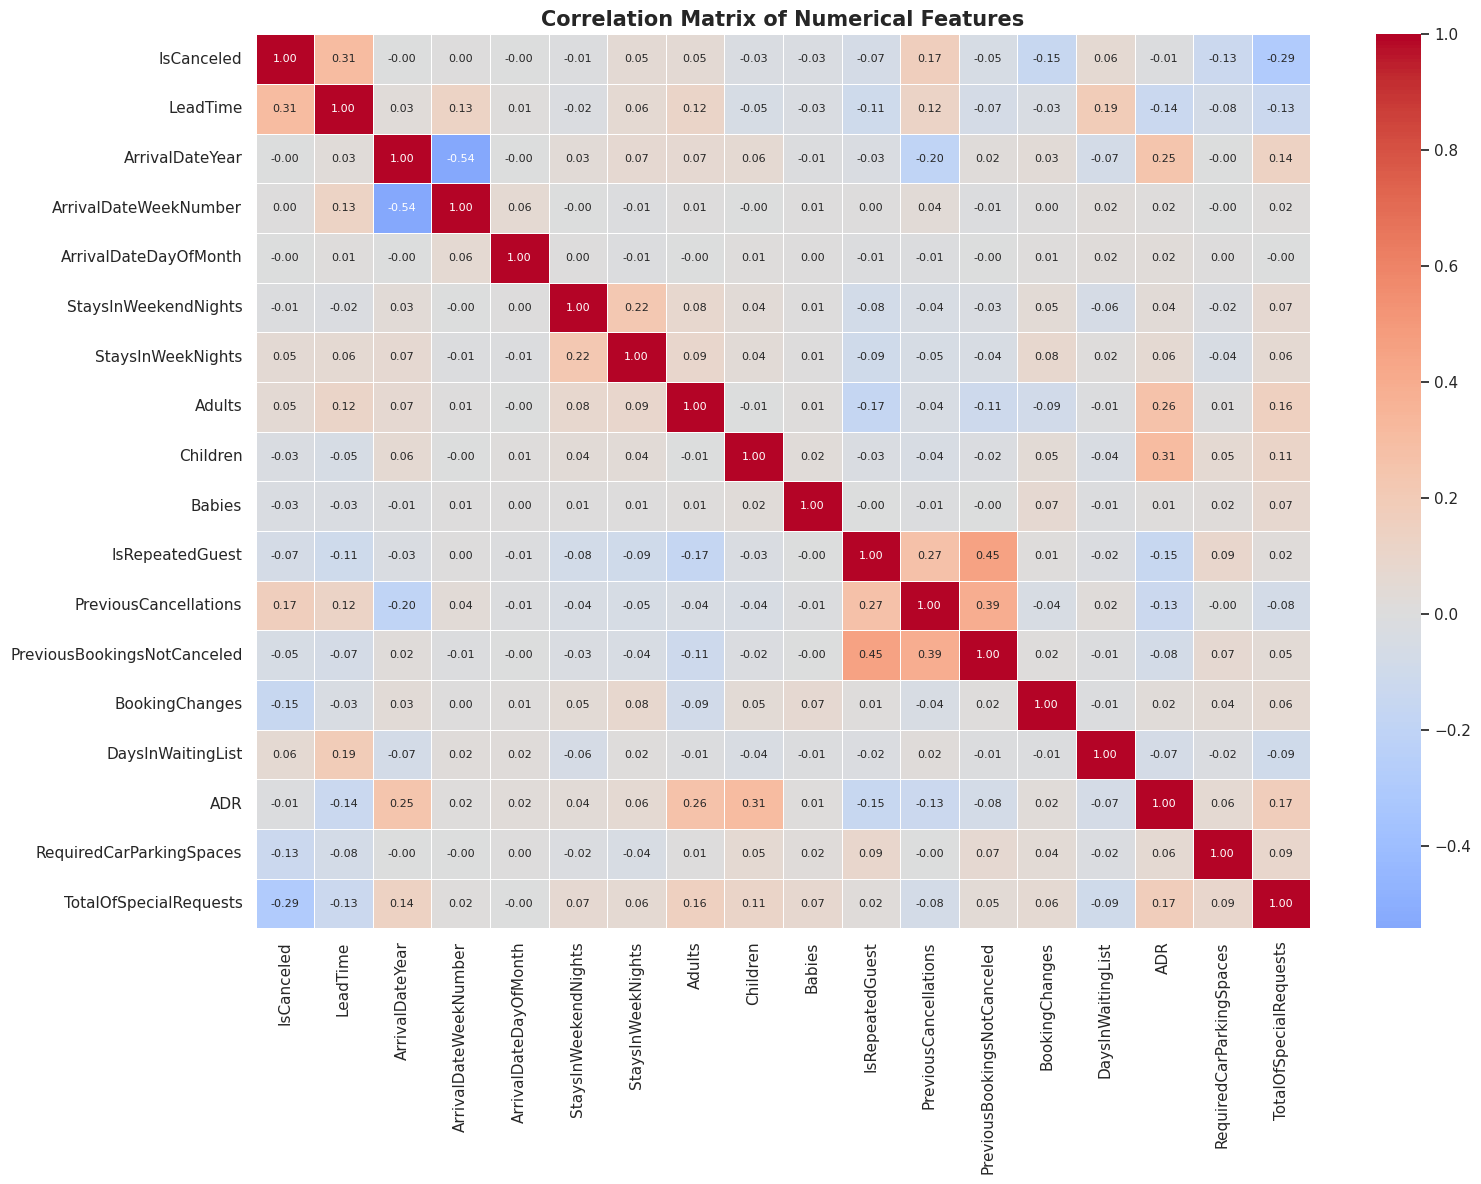

In [15]:
# Task 3.7: Numerical Correlation Analysis

numeric_df = df.select_dtypes(
    include=["number"]
)

correlation_matrix = numeric_df.corr(
    method="pearson"
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title(
    "Correlation Matrix of Numerical Features",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

,Pearson Correlation
TotalOfSpecialRequests,-0.294
BookingChanges,-0.149
RequiredCarParkingSpaces,-0.133
IsRepeatedGuest,-0.066
PreviousBookingsNotCanceled,-0.053
Babies,-0.030
Children,-0.027
ADR,-0.012
StaysInWeekendNights,-0.007
ArrivalDateDayOfMonth,-0.004


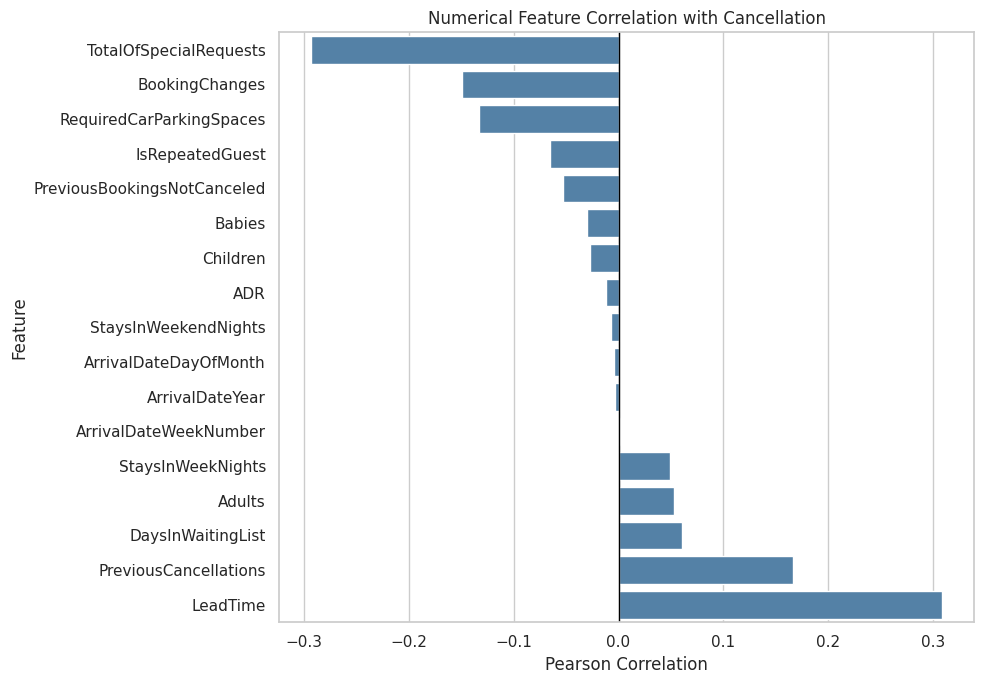

In [16]:
# Task 3.8: Correlation with IsCanceled

cancellation_corr = (
    correlation_matrix["IsCanceled"]
    .drop("IsCanceled")
    .sort_values()
)

display(
    cancellation_corr.to_frame(
        name="Pearson Correlation"
    ).round(3)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=cancellation_corr.values,
    y=cancellation_corr.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Numerical Feature Correlation with Cancellation"
)

plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()